# 01 - Préparation et exploration des données

Objectif : préparer les données Bank Marketing pour le clustering (chapitre 1 du cours).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

import sys
sys.path.insert(0, "..")
import fonctions

## 1. La matrice de données

Une ligne = un client, une colonne = une variable.

In [2]:
df_brut = pd.read_csv("../data/bank-additional-full.csv", sep=";")
print("Nombre de clients :", df_brut.shape[0])
print("Nombre de colonnes :", df_brut.shape[1])
print("Nombre de doublons :", df_brut.duplicated().sum())
df_brut.head()

Nombre de clients : 41188
Nombre de colonnes : 21
Nombre de doublons : 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Types de variables

| Type | Variables |
|---|---|
| Numérique continue | age, duration, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed |
| Numérique discrète | campaign, pdays, previous |
| Nominale | job, marital, month, day_of_week, poutcome |
| Ordinale | education |
| Binaire | contact, default, housing, loan, et la cible y |

In [3]:
# on charge les données sans doublons et on met la cible y de côté
df, y = fonctions.charger_donnees()
print("Clients après suppression des doublons :", len(df))
print("Taux de souscription :", round(y.mean() * 100, 1), "%")

Clients après suppression des doublons : 41176
Taux de souscription : 11.3 %


## 3. Nettoyage

Les valeurs manquantes sont écrites "unknown".

In [4]:
# nombre de "unknown" par variable
for colonne in df.columns:
    nb = (df[colonne] == "unknown").sum()
    if nb > 0:
        print(colonne, ":", nb)

job : 330
marital : 80
education : 1730
default : 8596
housing : 990
loan : 990


On garde "unknown" comme une catégorie : 21 % des clients ont default = unknown, on ne peut pas tous les supprimer.

La variable campaign (nombre d'appels) a des valeurs très grandes :

count    41176.000000
mean         2.567879
std          2.770318
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64
99e centile : 14.0


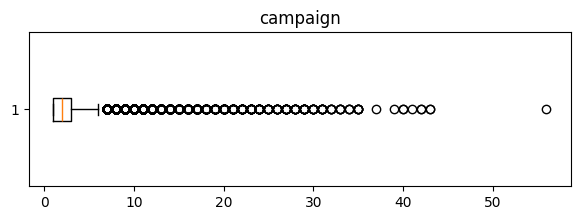

In [5]:
print(df["campaign"].describe())
print("99e centile :", df["campaign"].quantile(0.99))

plt.figure(figsize=(7, 2))
plt.boxplot(df["campaign"], vert=False)
plt.title("campaign")
plt.show()

On limite campaign à 14 appels (99e centile).

## 4. Exploration

In [6]:
numeriques = df.select_dtypes("number").columns
df[numeriques].describe().round(2)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00,41176.00
mean,40.02,258.32,2.57,962.46,0.17,0.08,93.58,-40.50,3.62,5167.03
std,10.42,259.31,2.77,186.94,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


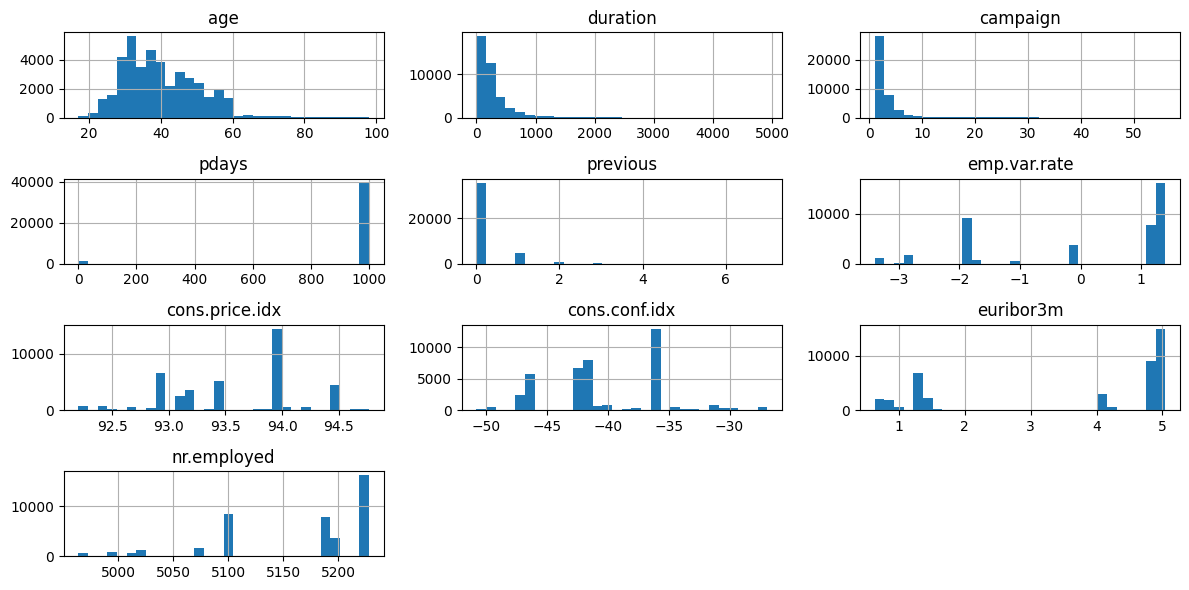

In [7]:
df[numeriques].hist(bins=30, figsize=(12, 6))
plt.tight_layout()
plt.show()

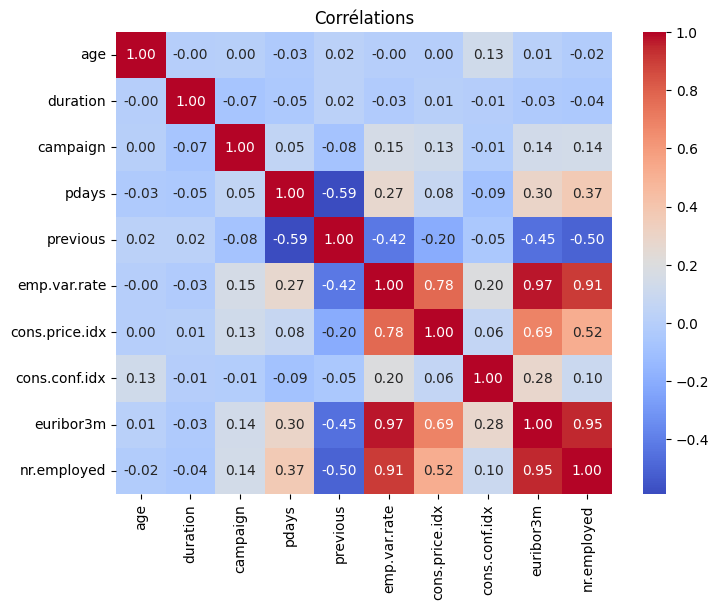

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeriques].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Corrélations")
plt.show()

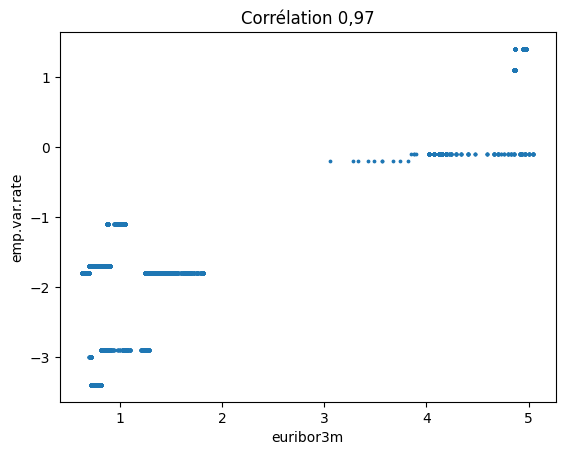

In [9]:
# deux indicateurs économiques presque identiques
plt.scatter(df["euribor3m"], df["emp.var.rate"], s=3)
plt.xlabel("euribor3m")
plt.ylabel("emp.var.rate")
plt.title("Corrélation 0,97")
plt.show()

## 5. Choix des variables

On retire 6 variables :

- duration : connue seulement après l'appel ;
- month, day_of_week : la date de l'appel, pas le client ;
- pdays : 96 % des valeurs valent 999 (un code qui veut dire "jamais contacté") ;
- emp.var.rate, nr.employed : corrélées à plus de 0,9 avec euribor3m.

Il reste 14 variables : 6 numériques et 8 catégorielles.

In [10]:
df_propre = fonctions.nettoyer(df)
X, y_ech = fonctions.echantillonner(df_propre, y)   # 4 000 clients

print("Variables gardées :", list(X.columns))
print("Taille de l'échantillon :", len(X))
print("Taux de souscription (toutes les données) :", round(y.mean() * 100, 2), "%")
print("Taux de souscription (échantillon) :", round(y_ech.mean() * 100, 2), "%")

Variables gardées : ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'campaign', 'previous', 'poutcome', 'cons.price.idx', 'cons.conf.idx', 'euribor3m']
Taille de l'échantillon : 4000
Taux de souscription (toutes les données) : 11.27 %
Taux de souscription (échantillon) : 11.28 %


## 6. Deux représentations

(a) one-hot + standardisation : $z = \dfrac{x - \mu}{\sigma}$

(b) données mixtes brutes (pour la distance de Gower et K-prototypes)

In [11]:
Xa = fonctions.representation_a(X)
Xb = fonctions.representation_b(X)
print("Représentation (a) :", Xa.shape)
print("Représentation (b) :", Xb.shape)

Représentation (a) : (4000, 43)
Représentation (b) : (4000, 14)


## 7. Réduction de dimension

- PCA : garde le maximum de variance.
- t-SNE et UMAP : gardent les voisins proches, pour visualiser en 2D.

Composantes pour 80 % de la variance : 10


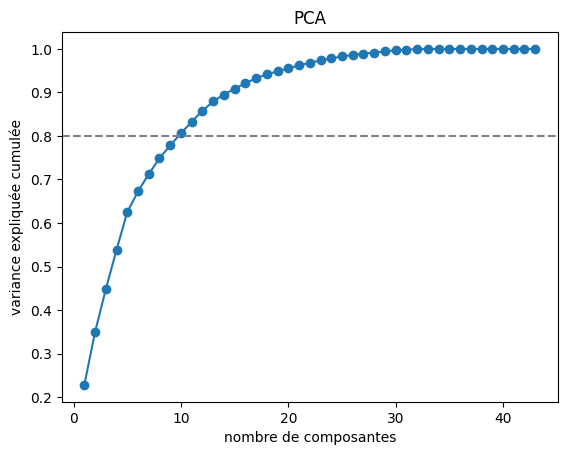

In [12]:
pca = PCA()
pca.fit(Xa)
variance_cumulee = np.cumsum(pca.explained_variance_ratio_)
print("Composantes pour 80 % de la variance :", np.argmax(variance_cumulee >= 0.8) + 1)

plt.plot(range(1, len(variance_cumulee) + 1), variance_cumulee, marker="o")
plt.axhline(0.8, color="gray", linestyle="--")
plt.xlabel("nombre de composantes")
plt.ylabel("variance expliquée cumulée")
plt.title("PCA")
plt.show()

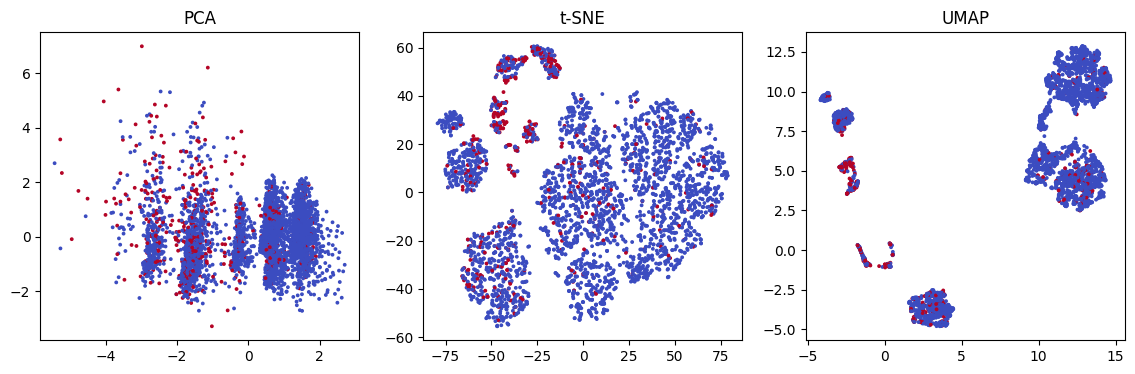

In [13]:
pca_2d = PCA(n_components=2, random_state=42).fit_transform(Xa)
tsne_2d = TSNE(n_components=2, random_state=42).fit_transform(Xa)
umap_2d = umap.UMAP(n_components=2, random_state=42).fit_transform(Xa)

# couleur : rouge = a souscrit (seulement pour regarder)
plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=y_ech, cmap="coolwarm", s=3)
plt.title("PCA")
plt.subplot(1, 3, 2)
plt.scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=y_ech, cmap="coolwarm", s=3)
plt.title("t-SNE")
plt.subplot(1, 3, 3)
plt.scatter(umap_2d[:, 0], umap_2d[:, 1], c=y_ech, cmap="coolwarm", s=3)
plt.title("UMAP")
plt.show()

Les clients qui ont souscrit (en rouge) sont dispersés : aucune projection ne les sépare.

## 8. Fonction réutilisable

Toutes ces étapes sont dans `fonctions.preparer()`. On vérifie qu'elle donne le même résultat :

In [14]:
X2, y2, Xa2, Xb2 = fonctions.preparer()
print(np.allclose(Xa, Xa2))

True
